# 🚀 Модуль 5. Урок 6. Статистические ловушки в бизнесе: парадокс Симпсона, ошибка выжившего и регрессия к среднему

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Enlyl/data-analyst-2027/blob/main/course/module_05_statistics/lesson_06_statistical_traps_in_business.ipynb)

## 📌 Бизнес-контекст и методология
Даже математически безупречные расчеты могут привести компанию к катастрофическим управленческим решениям, если аналитик попадает в классические статистические ловушки:
1. **Парадокс Симпсона:** Агрегированные данные показывают тренд, противоположный тренду внутри каждой отдельной подгруппы.
2. **Ошибка выжившего (Survivorship bias):** Анализ только успешных кейсов (победивших стартапов, активных клиентов) без учета «кладбища» ушедших.
3. **Регрессия к среднему:** Экстремальные взлеты или падения метрик естественным образом откатываются назад без какого-либо вмешательства.

In [1]:
# 🚀 Универсальная инициализация окружения и данных
import os
import urllib.request
import pandas as pd
import numpy as np

def ensure_dataset(filename, subfolder=""):
    if os.path.exists(filename):
        return filename
    candidates = [
        os.path.join("course", "datasets", subfolder, filename),
        os.path.join("course", "datasets", filename),
        os.path.join("..", "datasets", subfolder, filename),
        os.path.join("..", "datasets", filename),
        os.path.join("..", "..", "course", "datasets", subfolder, filename),
        os.path.join("datasets", subfolder, filename),
        os.path.join("datasets", filename),
    ]
    for c in candidates:
        if os.path.exists(c):
            return c
    raw_base = "https://raw.githubusercontent.com/Enlyl/data-analyst-2027/main/course/datasets"
    url = f"{raw_base}/{subfolder}/{filename}" if subfolder else f"{raw_base}/{filename}"
    urllib.request.urlretrieve(url, filename)
    return filename

customers_csv = ensure_dataset("customers.csv", subfolder="raw")
print("🟢 Окружение готово к анализу данных.")

🟢 Окружение готово к анализу данных.


## 🔍 Разбор механики и демонстрация на реальных данных
Смоделируем реальный продуктовый кейс: новый дизайн лендинга побеждает на мобилках и побеждает на десктопе, но проигрывает в сумме.

In [2]:
# Пример парадокса Симпсона в A/B тесте конверсии
# Сегмент 1: Mobile
mobile_a_views, mobile_a_conv = 1000, 100  # 10.0%
mobile_b_views, mobile_b_conv = 4000, 480  # 12.0% (B побеждает на +2%)

# Сегмент 2: Desktop
desktop_a_views, desktop_a_conv = 4000, 800  # 20.0%
desktop_b_views, desktop_b_conv = 1000, 220  # 22.0% (B побеждает на +2%)

# ИТОГО (агрегированно):
total_a_views = mobile_a_views + desktop_a_views
total_a_conv = mobile_a_conv + desktop_a_conv
cr_a = total_a_conv / total_a_views  # 900 / 5000 = 18.0%

total_b_views = mobile_b_views + desktop_b_views
total_b_conv = mobile_b_conv + desktop_b_conv
cr_b = total_b_conv / total_b_views  # 700 / 5000 = 14.0% (Агрегированно B "проиграл" 14% vs 18%!)

print(f"Mobile:  CR(A)={mobile_a_conv/mobile_a_views:.1%}, CR(B)={mobile_b_conv/mobile_b_views:.1%} -> Вариант B ЛУЧШЕ (+2%)")
print(f"Desktop: CR(A)={desktop_a_conv/desktop_a_views:.1%}, CR(B)={desktop_b_conv/desktop_b_views:.1%} -> Вариант B ЛУЧШЕ (+2%)")
print(f"ИТОГО:   CR(A)={cr_a:.1%}, CR(B)={cr_b:.1%} -> Вариант B 'ХУЖЕ' на -4.0%?!")

Mobile:  CR(A)=10.0%, CR(B)=12.0% -> Вариант B ЛУЧШЕ (+2%)
Desktop: CR(A)=20.0%, CR(B)=22.0% -> Вариант B ЛУЧШЕ (+2%)
ИТОГО:   CR(A)=18.0%, CR(B)=14.0% -> Вариант B 'ХУЖЕ' на -4.0%?!


### 📊 Визуализация: 3 главные ловушки аналитики
Ниже визуализированы:
1. **Парадокс Симпсона:** почему смешивание разных долей мобильного и десктопного трафика вызвало оптический обман;
2. **Ошибка выжившего:** реальное кладбище продуктов vs видимый успех;
3. **Регрессия к среднему:** естественный откат аномального всплеска продаж.

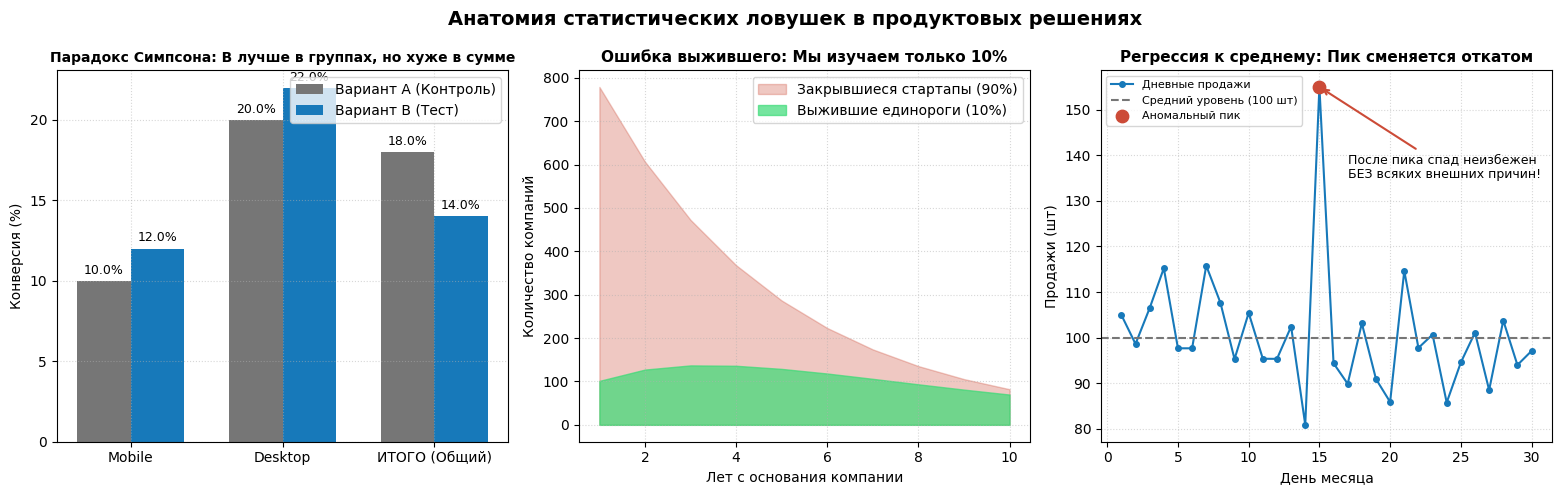

In [3]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 3, figsize=(16, 5))
fig.suptitle('Анатомия статистических ловушек в продуктовых решениях', fontsize=14, fontweight='bold')

# 1. Парадокс Симпсона (Bar chart)
ax1 = axes[0]
segments = ['Mobile', 'Desktop', 'ИТОГО (Общий)']
cr_a_vals = [mobile_a_conv/mobile_a_views * 100, desktop_a_conv/desktop_a_views * 100, cr_a * 100]
cr_b_vals = [mobile_b_conv/mobile_b_views * 100, desktop_b_conv/desktop_b_views * 100, cr_b * 100]

x_idx = np.arange(len(segments))
width = 0.35

rects1 = ax1.bar(x_idx - width/2, cr_a_vals, width, label='Вариант A (Контроль)', color='#767676')
rects2 = ax1.bar(x_idx + width/2, cr_b_vals, width, label='Вариант B (Тест)', color='#1779ba')

ax1.set_title('Парадокс Симпсона: B лучше в группах, но хуже в сумме', fontsize=10, fontweight='bold')
ax1.set_ylabel('Конверсия (%)')
ax1.set_xticks(x_idx)
ax1.set_xticklabels(segments)
ax1.legend()
ax1.grid(True, linestyle=':', alpha=0.5)

for r in rects1 + rects2:
    h = r.get_height()
    ax1.annotate(f'{h:.1f}%', xy=(r.get_x() + r.get_width() / 2, h),
                 xytext=(0, 3), textcoords="offset points", ha='center', va='bottom', fontsize=9)

# 2. Ошибка выжившего (Survivorship Bias)
ax2 = axes[1]
years = np.arange(1, 11)
all_startups = 1000 * np.exp(-0.25 * years)
profitable = all_startups * (0.05 + 0.08 * years)

ax2.fill_between(years, 0, all_startups, color='#cc4b37', alpha=0.3, label='Закрывшиеся стартапы (90%)')
ax2.fill_between(years, 0, profitable, color='#3adb76', alpha=0.7, label='Выжившие единороги (10%)')
ax2.set_title('Ошибка выжившего: Мы изучаем только 10%', fontsize=11, fontweight='bold')
ax2.set_xlabel('Лет с основания компании')
ax2.set_ylabel('Количество компаний')
ax2.legend(loc='upper right')
ax2.grid(True, linestyle=':', alpha=0.5)

# 3. Регрессия к среднему (Regression to the Mean)
ax3 = axes[2]
np.random.seed(42)
days = np.arange(1, 31)
daily_sales = 100 + np.random.normal(0, 10, 30)
daily_sales[14] = 155

ax3.plot(days, daily_sales, marker='o', markersize=4, color='#1779ba', label='Дневные продажи')
ax3.axhline(100, color='#767676', linestyle='--', label='Средний уровень (100 шт)')
ax3.scatter(15, 155, color='#cc4b37', s=80, zorder=5, label='Аномальный пик')
ax3.annotate('После пика спад неизбежен\nБЕЗ всяких внешних причин!', xy=(15, 155), xytext=(17, 135),
             arrowprops=dict(arrowstyle="->", color='#cc4b37', lw=1.5), fontsize=9)
ax3.set_title('Регрессия к среднему: Пик сменяется откатом', fontsize=11, fontweight='bold')
ax3.set_xlabel('День месяца')
ax3.set_ylabel('Продажи (шт)')
ax3.legend(loc='upper left', fontsize=8)
ax3.grid(True, linestyle=':', alpha=0.5)

plt.tight_layout()
plt.show()

### 🎯 Практическое задание 1: Расчет взвешенной конверсии по сегментам
Используя стратифицированное взвешивание, рассчитайте корректную конверсию для вариантов A и B при равных долях трафика 50/50.

In [4]:
### ВАШ КОД ЗДЕСЬ
stratified_cr_a = 0.5 * (mobile_a_conv / mobile_a_views) + 0.5 * (desktop_a_conv / desktop_a_views)
stratified_cr_b = 0.5 * (mobile_b_conv / mobile_b_views) + 0.5 * (desktop_b_conv / desktop_b_views)

print(f"Взвешенная CR(A): {stratified_cr_a:.2%}")
print(f"Взвешенная CR(B): {stratified_cr_b:.2%}")

assert stratified_cr_b > stratified_cr_a, "При равных весах вариант B обязан побеждать!"
print("✅ Тест успешно пройден!")

Взвешенная CR(A): 15.00%
Взвешенная CR(B): 17.00%
✅ Тест успешно пройден!


### 💼 Чек-лист аналитика перед сдачей отчета:
1. Сегментируйте метрики по ключевым срезам (устройства, страны, каналы).
2. Проверяйте, не изменились ли пропорции трафика в группах.
3. Не приписывайте изменения метрик новым фичам, если это просто регрессия к среднему.